In [57]:
3+3

6

In [58]:
import pandas as pd
from pathlib import Path

project_dir = Path(r"C:\Users\rcorb\OneDrive\Desktop\STUDIO 2\2nd_Half_Book_Project")
matches = list(project_dir.rglob("books.csv"))

if not matches:
    raise FileNotFoundError(f"books.csv was not found in {project_dir}")

books = pd.read_csv(
    matches[0],
    engine="python",
    on_bad_lines="warn"
)

books.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


In [59]:
books.columns.tolist()

['bookID',
 'title',
 'authors',
 'average_rating',
 'isbn',
 'isbn13',
 'language_code',
 'num_pages',
 'ratings_count',
 'text_reviews_count',
 'publication_date',
 'publisher']

In [60]:
books.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11115 entries, 0 to 11114
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              11115 non-null  int64  
 1   title               11115 non-null  object 
 2   authors             11115 non-null  object 
 3   average_rating      11115 non-null  float64
 4   isbn                11115 non-null  object 
 5   isbn13              11115 non-null  int64  
 6   language_code       11115 non-null  object 
 7   num_pages           11115 non-null  int64  
 8   ratings_count       11115 non-null  int64  
 9   text_reviews_count  11115 non-null  int64  
 10  publication_date    11115 non-null  object 
 11  publisher           11115 non-null  object 
dtypes: float64(1), int64(5), object(6)
memory usage: 1.0+ MB


In [61]:
def random_book_details(books):
    random_books = books.sample(n=10)

    for _, book in random_books.iterrows():
        print(f"- Publication date: {book['publication_date']}")
        print(f"  - Title: {book['title']}")
        print(f"  - Author(s): {book['authors']}")
        print(f"  - Average rating: {book['average_rating']}")
        print(f"  - Page number: {book['num_pages']}")


In [62]:
random_book_details(books)

- Publication date: 4/1/2006
  - Title: It's Kind of a Funny Story
  - Author(s): Ned Vizzini
  - Average rating: 4.13
  - Page number: 444
- Publication date: 1/30/2007
  - Title: Black Lamb and Grey Falcon
  - Author(s): Rebecca West/Christopher Hitchens
  - Average rating: 4.23
  - Page number: 1181
- Publication date: 9/13/2005
  - Title: Fullmetal Alchemist  Vol. 3 (Fullmetal Alchemist  #3)
  - Author(s): Hiromu Arakawa/Akira Watanabe
  - Average rating: 4.56
  - Page number: 192
- Publication date: 11/6/2003
  - Title: The Turn of the Screw
  - Author(s): Henry James/Peter G. Beidler
  - Average rating: 3.43
  - Page number: 386
- Publication date: 5/2/2006
  - Title: The Hidden Family (The Merchant Princes  #2)
  - Author(s): Charles Stross
  - Average rating: 3.57
  - Page number: 309
- Publication date: 8/6/2001
  - Title: Brightness Falls
  - Author(s): Jay McInerney
  - Average rating: 3.74
  - Page number: 432
- Publication date: 11/26/2002
  - Title: Worlds Enough & Time: 

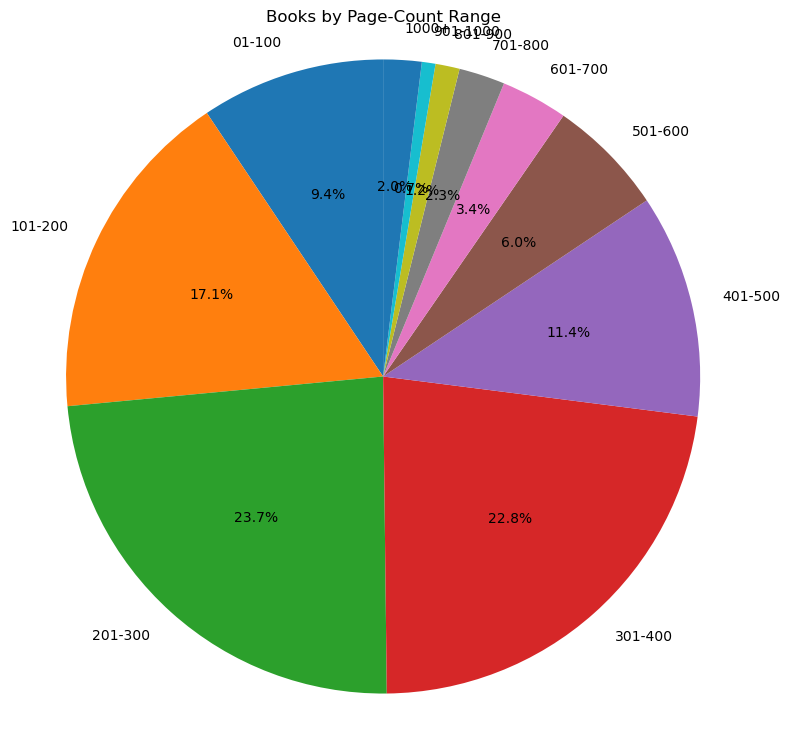

In [63]:
import matplotlib.pyplot as plt

bins = [0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, float("inf")]
labels = [
    "01-100", "101-200", "201-300", "301-400", "401-500",
    "501-600", "601-700", "701-800", "801-900", "901-1000", "1000+"
]

page_ranges = pd.cut(
    books["num_pages"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

page_counts = page_ranges.value_counts().reindex(labels)

plt.figure(figsize=(9, 9))
plt.pie(
    page_counts,
    labels=page_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Books by Page-Count Range")
plt.axis("equal")
plt.show()

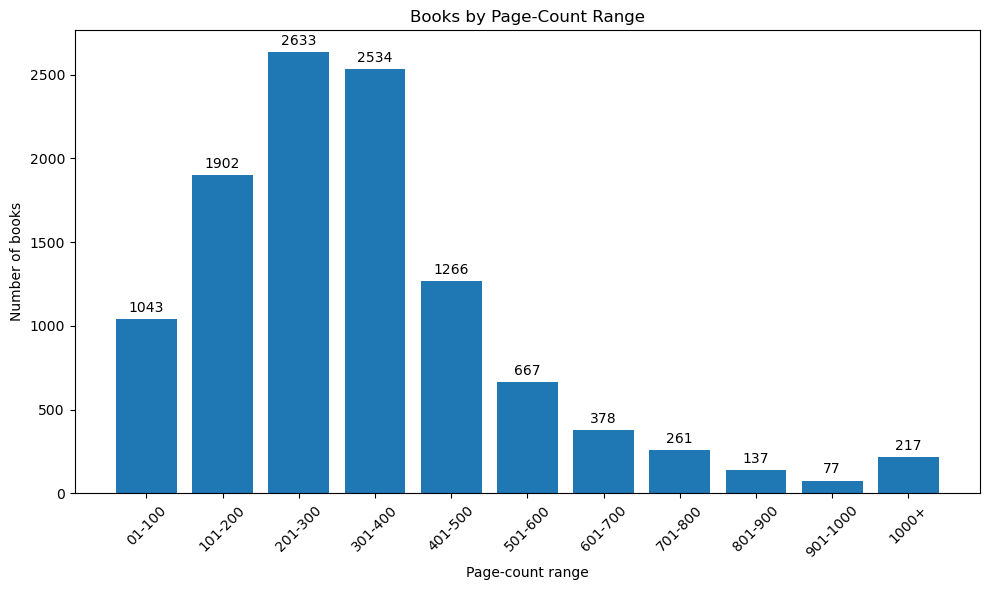

In [64]:
plt.figure(figsize=(10, 6))

bars = plt.bar(page_counts.index, page_counts.values)

plt.bar_label(bars, labels=page_counts.values, padding=3)

plt.title("Books by Page-Count Range")
plt.xlabel("Page-count range")
plt.ylabel("Number of books")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

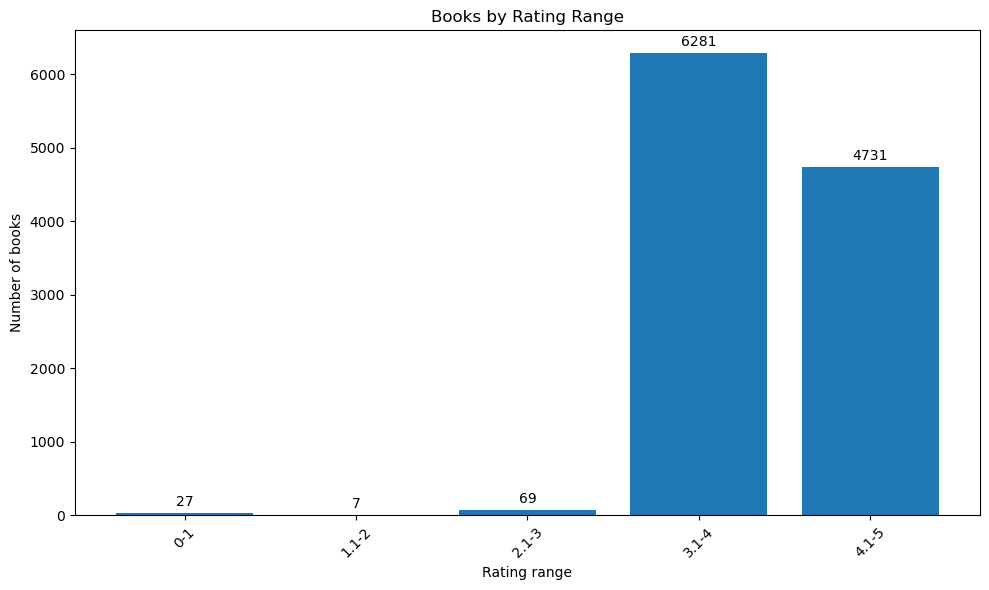

In [65]:
rating_ranges = pd.cut(
    books["average_rating"],
    bins=[0, 1, 2, 3, 4, 5],
    labels=["0-1", "1.1-2", "2.1-3", "3.1-4", "4.1-5"],
    include_lowest=True
)

rating_counts = rating_ranges.value_counts().sort_index()

plt.figure(figsize=(10, 6))

bars = plt.bar(rating_counts.index, rating_counts.values)

plt.bar_label(bars, labels=rating_counts.values, padding=3)

plt.title("Books by Rating Range")
plt.xlabel("Rating range")
plt.ylabel("Number of books")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()